In [10]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import os
import json
import seaborn as sns


In [26]:
# base_filepath = '/Volumes/mrsic_flogel/public/projects/SaReSuKu_20240722_HeadFixedSchemaImaging/rawdata/sub-TAA0000117/ses-001/funcimg/910nm/20250624_151550__TAA0000117_00001/suite2p/'
# base_filepath = '/Volumes/behrens/meg/3x3_field_magnitude_bandit/derivatives/cohort-01/sub-03_id-MY_71_R/ses-177_date-20260624/funcimg/destriped_distortion_corrected/suite2p/'
# base_filepath = '/Volumes/behrens/meg/3x3_field_magnitude_bandit/derivatives/cohort-01/sub-03_id-MY_71_R/ses-177_date-20260624/funcimg/striped_distortion_uncorrected/suite2p/'
# base_filepath = '/Volumes/behrens/meg/3x3_field_magnitude_bandit/derivatives/cohort-01/sub-03_id-MY_71_R/ses-177_date-20260624/funcimg/destriped_distortion_uncorrected/suite2p/'
# base_filepath = '/Volumes/behrens/meg/3x3_field_magnitude_bandit/derivatives/cohort-01/sub-05_id-MY_72_L/ses-169_date-20260621/funcimg/destriped_distortion_corrected/suite2p/'
# base_filepath = '/Volumes/behrens/meg/3x3_field_magnitude_bandit/derivatives/cohort-01/sub-05_id-MY_72_L/ses-169_date-20260621/funcimg/striped_distortion_uncorrected/suite2p/'
# base_filepath = '/Volumes/behrens/meg/3x3_field_magnitude_bandit/derivatives/cohort-01/sub-05_id-MY_72_L/ses-169_date-20260621/funcimg/destriped_distortion_uncorrected/suite2p/'
# base_filepath = '/Volumes/behrens/meg/3x3_field_magnitude_bandit/rawdata/sub-01_id-M14/ses-02_date-20260506/funcimg/suite2p/'
base_filepath = '/Volumes/behrens/meg/3x3_field_magnitude_bandit/derivatives/cohort-01/sub-03_id-MY_71_R/ses-216_date-20260730/funcimg/run-03/suite2p/'
proc_path = 'plane0/'
file = 'ops.npy'

dict_keys(['data_path', 'look_one_level_down', 'input_format', 'keep_movie_raw', 'nplanes', 'nrois', 'nchannels', 'swap_order', 'functional_chan', 'lines', 'dy', 'dx', 'ignore_flyback', 'subfolders', 'file_list', 'save_path0', 'fast_disk', 'save_folder', 'h5py_key', 'nwb_driver', 'nwb_series', 'force_sktiff', 'bruker_bidirectional', 'batch_size', 'first_files', 'save_path', 'settings_path', 'db_path', 'reg_file', 'iplane', 'reg_file_chan2', 'Ly', 'Lx', 'nframes', 'frames_per_file', 'frames_per_folder', 'meanImg', 'meanImg_chan2', 'torch_device', 'tau', 'fs', 'diameter', 'run', 'io', 'registration', 'detection', 'classification', 'extraction', 'dcnv_preprocess', 'version', 'date_proc', 'refImg', 'rmin', 'rmax', 'yoff', 'xoff', 'corrXY', 'yoff1', 'xoff1', 'corrXY1', 'badframes', 'badframes0', 'yrange', 'xrange', 'bidiphase', 'meanImgE', 'plane_times'])


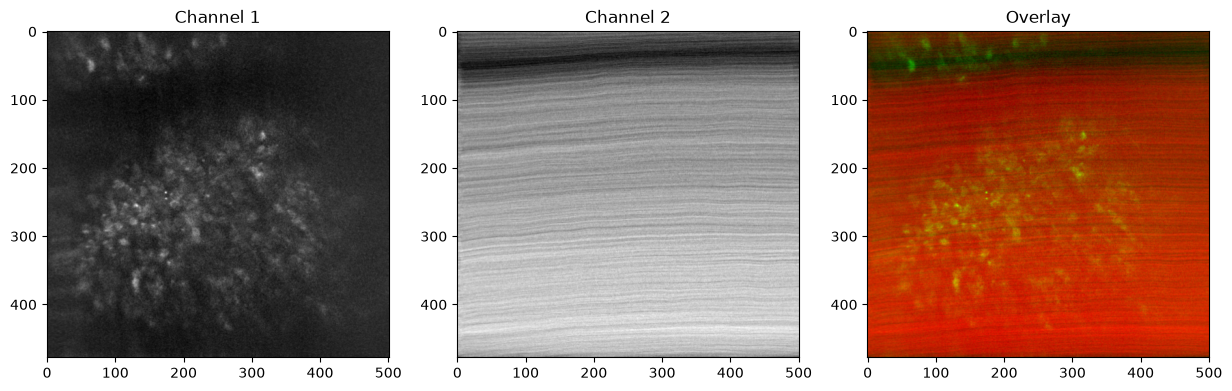

In [27]:
settings = np.load(os.path.join(base_filepath, proc_path, file), allow_pickle=True).item()
print(settings.keys())
img1 = settings['meanImg']
img2 = settings['meanImg_chan2']
#make an image overlay with the two channels
img1 = np.squeeze(img1)
img2 = np.squeeze(img2)
# Normalize images
img1 = (img1 - np.min(img1)) / (np.max(img1) - np.min(img1))
img2 = (img2 - np.min(img2)) / (np.max(img2) - np.min(img2))
# Create an overlay image
#img1 is the green channel, img2 is the red channel
img_overlay = np.zeros((img1.shape[0], img1.shape[1], 3), dtype=np.float32)
img_overlay[..., 0] = img2  # Red channel
img_overlay[..., 1] = img1  # Green channel

img_overlay[..., 0] = img2  # Red channel
img_overlay[..., 1] = img1 # Green channel

fig, (ax1,ax2,ax3) = plt.subplots(1, 3, figsize=(15, 10))
ax1.imshow(img1, cmap='gray')
ax2.imshow(img2, cmap='gray')   
# Display the overlay image as an RGB image
ax3.imshow(img_overlay)
ax1.set_title('Channel 1')
ax2.set_title('Channel 2')
ax3.set_title('Overlay')
plt.show()

## Interactive contrast for both Suite2p mean images

The upper controls adjust `meanImg` (the functional green stream, physical acquisition channel 2). The lower controls independently adjust `meanImg_chan2` (the structural red stream, physical acquisition channel 1). Black and white values are percentile-based and gamma changes midtones. These controls affect display and exported PNGs only; they do not modify Suite2p data.


In [28]:
# If this import fails, run: %pip install ipywidgets
from pathlib import Path
import ipywidgets as widgets
from IPython.display import display

mean_ch1_raw = np.squeeze(np.asarray(settings["meanImg"], dtype=np.float32))
if "meanImg_chan2" not in settings:
    raise KeyError(
        "ops.npy has no 'meanImg_chan2'. Confirm that this Suite2p run used nchannels=2."
    )
mean_ch2_raw = np.squeeze(
    np.asarray(settings["meanImg_chan2"], dtype=np.float32))
if mean_ch1_raw.shape != mean_ch2_raw.shape:
    raise ValueError(
        f"Mean-image shape mismatch: {mean_ch1_raw.shape} versus {mean_ch2_raw.shape}"
    )


def scale_contrast(image, black_percentile, white_percentile, gamma):
    finite = image[np.isfinite(image)]
    black, white = np.percentile(
        finite, [black_percentile, white_percentile])
    if white <= black:
        raise ValueError(
            "White percentile must produce a value above the black percentile")
    scaled = np.clip((image - black) / (white - black), 0, 1) ** gamma
    return scaled, float(black), float(white)


def make_contrast_sliders(prefix):
    return (
        widgets.FloatSlider(
            value=5, min=0.0, max=50.0, step=0.5,
            description=f"{prefix} black %", continuous_update=False,
            readout_format=".1f", style={"description_width": "120px"}),
        widgets.FloatSlider(
            value=99.95, min=90.0, max=100.0, step=0.05,
            description=f"{prefix} white %", continuous_update=False,
            readout_format=".2f", style={"description_width": "120px"}),
        widgets.FloatSlider(
            value=1.2, min=0.2, max=3.0, step=0.05,
            description=f"{prefix} gamma", continuous_update=False,
            readout_format=".2f", style={"description_width": "120px"}),
    )


ch1_black_slider, ch1_white_slider, ch1_gamma_slider = (
    make_contrast_sliders("meanImg"))
ch2_black_slider, ch2_white_slider, ch2_gamma_slider = (
    make_contrast_sliders("chan2"))


def preview_contrast(ch1_black, ch1_white, ch1_gamma,
                     ch2_black, ch2_white, ch2_gamma):
    if ch1_white <= ch1_black or ch2_white <= ch2_black:
        print("Each white percentile must be greater than its black percentile")
        return
    ch1_display, ch1_low, ch1_high = scale_contrast(
        mean_ch1_raw, ch1_black, ch1_white, ch1_gamma)
    ch2_display, ch2_low, ch2_high = scale_contrast(
        mean_ch2_raw, ch2_black, ch2_white, ch2_gamma)

    fig, axes = plt.subplots(2, 2, figsize=(13, 11), constrained_layout=True)
    channel_rows = [
        (mean_ch1_raw, ch1_display, ch1_low, ch1_high, ch1_gamma,
         "meanImg — green functional (physical channel 2)"),
        (mean_ch2_raw, ch2_display, ch2_low, ch2_high, ch2_gamma,
         "meanImg_chan2 — red structural (physical channel 1)"),
    ]
    for row, (raw, adjusted, low, high, gamma, title) in enumerate(channel_rows):
        axes[row, 0].imshow(
            adjusted, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
        axes[row, 0].set_title(
            f"{title}\nvalues {low:.3g}–{high:.3g}; gamma={gamma:.2f}")
        axes[row, 0].axis("off")

        sample = raw.ravel()[::max(1, raw.size // 200_000)]
        sample = sample[np.isfinite(sample)]
        axes[row, 1].hist(sample, bins=256, color="0.35")
        axes[row, 1].axvline(low, color="tab:blue", label="black")
        axes[row, 1].axvline(high, color="tab:red", label="white")
        axes[row, 1].set_yscale("log")
        axes[row, 1].set_title(f"{title} raw intensity histogram")
        axes[row, 1].legend()
    plt.show()


contrast_controls = widgets.VBox([
    widgets.HTML("<b>meanImg — green functional / physical channel 2</b>"),
    ch1_black_slider, ch1_white_slider, ch1_gamma_slider,
    widgets.HTML("<b>meanImg_chan2 — red structural / physical channel 1</b>"),
    ch2_black_slider, ch2_white_slider, ch2_gamma_slider,
])
contrast_preview = widgets.interactive_output(
    preview_contrast,
    {
        "ch1_black": ch1_black_slider,
        "ch1_white": ch1_white_slider,
        "ch1_gamma": ch1_gamma_slider,
        "ch2_black": ch2_black_slider,
        "ch2_white": ch2_white_slider,
        "ch2_gamma": ch2_gamma_slider,
    },
)
display(contrast_controls, contrast_preview)


Output()

In [29]:
# Run this cell after choosing both sets of slider values.
meanImg_contrast, meanImg_black, meanImg_white = scale_contrast(
    mean_ch1_raw,
    ch1_black_slider.value,
    ch1_white_slider.value,
    ch1_gamma_slider.value,
)
meanImg_chan2_contrast, chan2_black, chan2_white = scale_contrast(
    mean_ch2_raw,
    ch2_black_slider.value,
    ch2_white_slider.value,
    ch2_gamma_slider.value,
)

plane0_path = Path(base_filepath) / proc_path
contrast_output_paths = {
    "meanImg PNG": plane0_path / "meanImg_green_physical_ch2_contrast.png",
    "meanImg_chan2 PNG": plane0_path / "meanImg_chan2_red_physical_ch1_contrast.png",
}
plt.imsave(
    contrast_output_paths["meanImg PNG"], meanImg_contrast,
    cmap="gray", vmin=0, vmax=1)
plt.imsave(
    contrast_output_paths["meanImg_chan2 PNG"], meanImg_chan2_contrast,
    cmap="gray", vmin=0, vmax=1)

contrast_settings = {
    "meanImg": {
        "description": "green functional; physical acquisition channel 2",
        "black_percentile": ch1_black_slider.value,
        "white_percentile": ch1_white_slider.value,
        "gamma": ch1_gamma_slider.value,
        "black_value": meanImg_black,
        "white_value": meanImg_white,
    },
    "meanImg_chan2": {
        "description": "red structural; physical acquisition channel 1",
        "black_percentile": ch2_black_slider.value,
        "white_percentile": ch2_white_slider.value,
        "gamma": ch2_gamma_slider.value,
        "black_value": chan2_black,
        "white_value": chan2_white,
    },
}
contrast_settings_path = plane0_path / "meanImg_contrast_settings.json"
contrast_settings_path.write_text(json.dumps(contrast_settings, indent=2))

for label, output_path in contrast_output_paths.items():
    print(f"Saved {label}: {output_path}")
print("Saved contrast settings:", contrast_settings_path)


Saved meanImg PNG: /Volumes/behrens/meg/3x3_field_magnitude_bandit/derivatives/cohort-01/sub-03_id-MY_71_R/ses-216_date-20260730/funcimg/run-03/suite2p/plane0/meanImg_green_physical_ch2_contrast.png
Saved meanImg_chan2 PNG: /Volumes/behrens/meg/3x3_field_magnitude_bandit/derivatives/cohort-01/sub-03_id-MY_71_R/ses-216_date-20260730/funcimg/run-03/suite2p/plane0/meanImg_chan2_red_physical_ch1_contrast.png
Saved contrast settings: /Volumes/behrens/meg/3x3_field_magnitude_bandit/derivatives/cohort-01/sub-03_id-MY_71_R/ses-216_date-20260730/funcimg/run-03/suite2p/plane0/meanImg_contrast_settings.json


In [30]:
print("nchannels:", settings.get("nchannels"))
print("functional_chan:", settings.get("functional_chan"))
print("align_by_chan:", settings.get("align_by_chan"))

print("\nKeys containing 'chan':")
for k in sorted(settings.keys()):
    if "chan" in k.lower():
        print(k)

nchannels: 2
functional_chan: 2
align_by_chan: None

Keys containing 'chan':
functional_chan
meanImg_chan2
nchannels
reg_file_chan2


In [31]:
from pathlib import Path

plane0 = Path(base_filepath) / proc_path

for path in sorted(plane0.iterdir()):
    if path.suffix == ".bin" or "chan" in path.name.lower():
        print(path.name)

data.bin
data_chan2.bin
meanImg_chan2_red_physical_ch1_contrast.png


In [32]:
save_ch1_name = 'meanImg_ch1.tiff'
plt.imsave(os.path.join(base_filepath, proc_path, save_ch1_name), img1, cmap='gray')

save_ch2_name = 'meanImg_ch2.tiff'
plt.imsave(os.path.join(base_filepath, proc_path, save_ch2_name), img2, cmap='gray')

save_overlay_name = 'meanImg_overlay.tiff'
plt.imsave(os.path.join(base_filepath, proc_path, save_overlay_name), img_overlay)

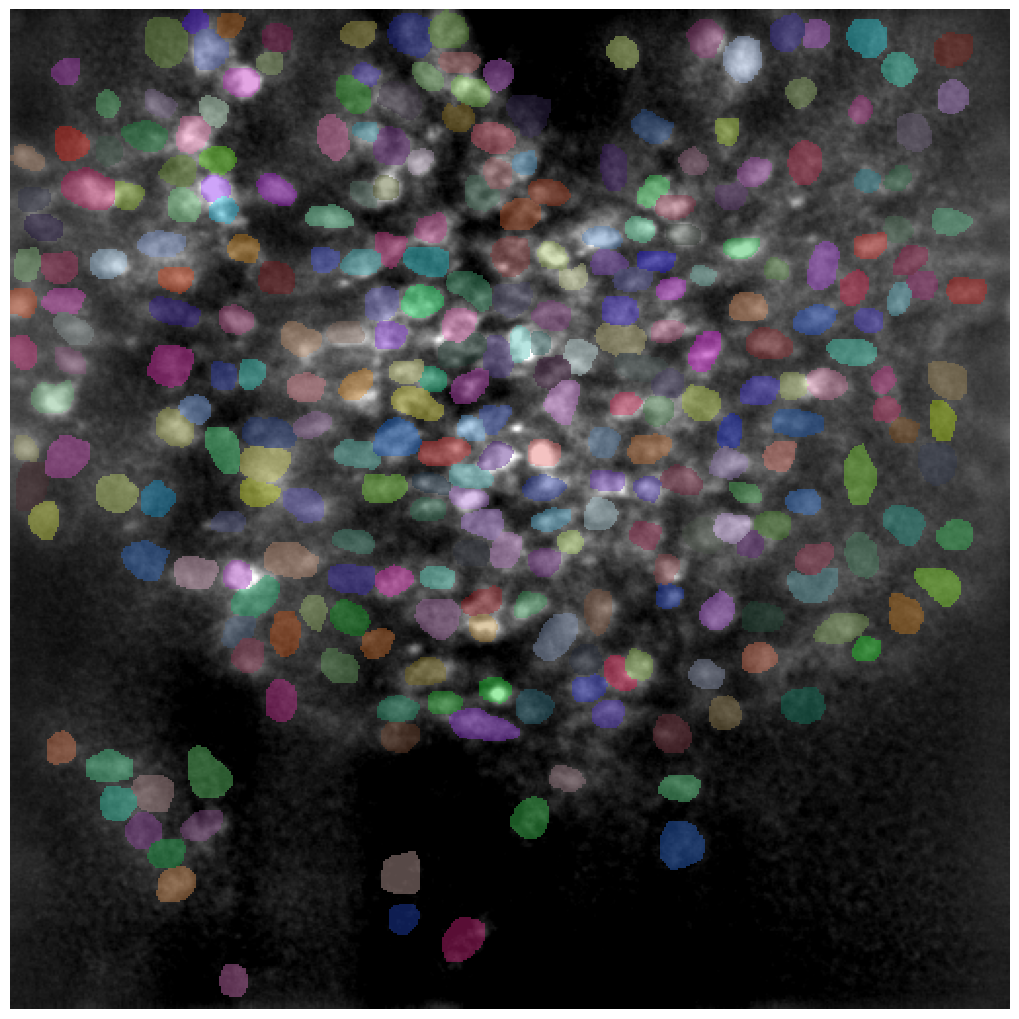

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

seg_path = Path("/Volumes/behrens/meg/3x3_field_magnitude_bandit/derivatives/cohort-01/sub-05_id-MY_72_L/ses-169_date-20260621/funcimg/destriped_distortion_uncorrected/suite2p/plane0/meanImg_ch1_seg.npy")
# seg_path = Path("/Volumes/behrens/meg/3x3_field_magnitude_bandit/derivatives/cohort-01/sub-03_id-MY_71_R/ses-177_date-20260624/funcimg/destriped_distortion_uncorrected/suite2p/plane0/meanImg_ch1_seg.npy")
output_path = seg_path.with_name("meanImg_ch1_cp_masks (1).png")

seg = np.load(seg_path, allow_pickle=True).item()

masks = np.asarray(seg["masks"])

# meanImg belongs to Suite2p's ops.npy, not the Cellpose *_seg.npy file.
ops_path = seg_path.with_name("ops.npy")
ops = np.load(ops_path, allow_pickle=True).item()
mean_image = np.asarray(ops["meanImg"])  # Suite2p channel 1

# Remove RGB/channel dimension if Cellpose stored a grayscale image as RGB
if mean_image.ndim == 3:
    mean_image = mean_image[..., 0]

if mean_image.shape != masks.shape:
    raise ValueError(
        f"Shape mismatch: meanImg is {mean_image.shape}, masks are {masks.shape}"
    )

# Fiji-like display scaling for the background image
black, white = np.percentile(mean_image, [10, 99.8])
display_image = np.clip((mean_image - black) / (white - black), 0, 1)

# Assign every Cellpose label an independent random vivid color.
# Use an integer seed for repeatable colors, or None for new colors each run.
MASK_COLOR_SEED = None
rng = np.random.default_rng(MASK_COLOR_SEED)
max_label = int(masks.max())
random_rgba = np.zeros((max_label + 1, 4), dtype=float)
if max_label > 0:
    random_rgba[1:, :3] = rng.uniform(0.05, 0.95, size=(max_label, 3))
    random_rgba[1:, 3] = 1.0
random_mask_cmap = ListedColormap(random_rgba)

# Hide label 0 so the background remains transparent.
overlay = np.ma.masked_where(masks == 0, masks)

fig, ax = plt.subplots(figsize=(10, 10))
ax.imshow(display_image, cmap="gray")
ax.imshow(
    overlay, cmap=random_mask_cmap, vmin=0, vmax=max(max_label, 1),
    alpha=0.40, interpolation="none")
ax.axis("off")

plt.tight_layout(pad=0)
fig.savefig(output_path, dpi=200, bbox_inches="tight", pad_inches=0)
plt.show()